<a href="https://colab.research.google.com/github/satapathysanchita783-afk/Machine-Learning-using-Colab/blob/main/Heart_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Create a data frame
df=pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df.shape

(1025, 14)

In [ ]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
#Checking missing values
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


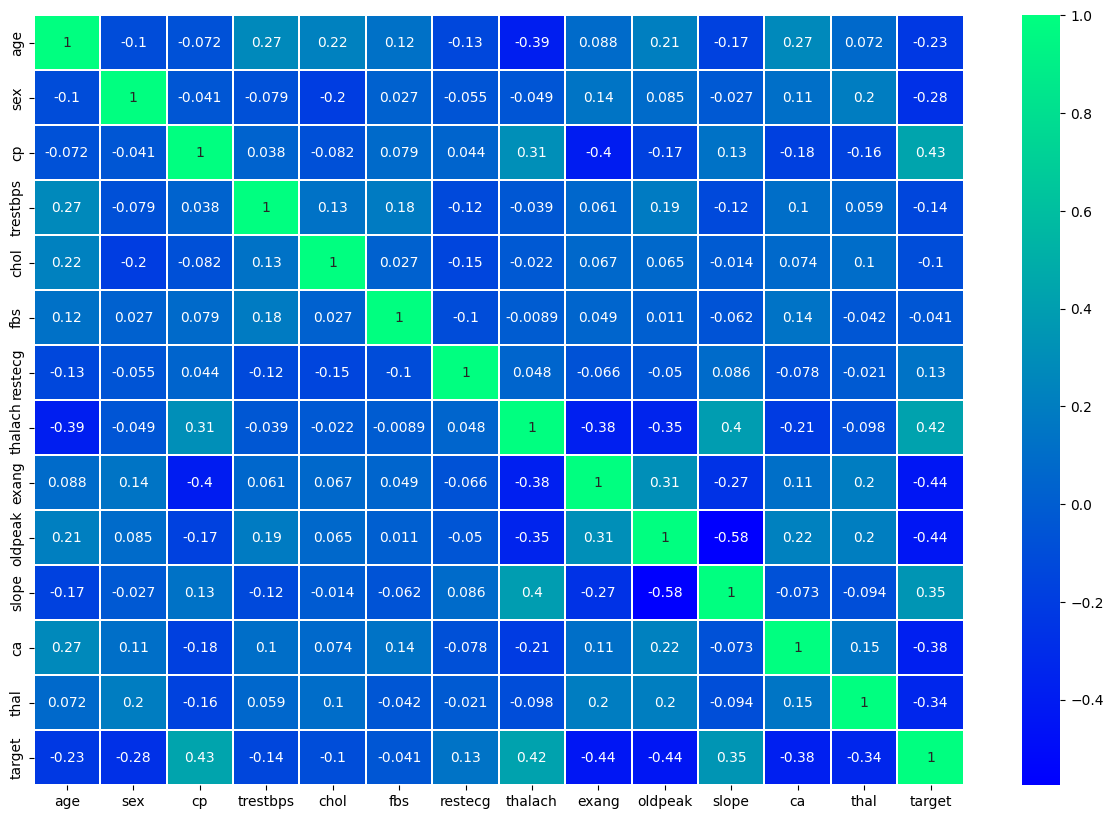

In [ ]:
#HeatMap
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(),linewidth=.01,annot=True,cmap="winter")
plt.show()

From the above heatmap, we are observing that the cpand target column have a positive correlation, which may indicate has a larger risk of chest pain that may results in a greater chance to have heart disease.

Apart that thalach, slope and restecg columns having a positive correlation with target column.

Then the exang, ca, oldpeak columns having a negative correlation with target column, so no chance for heart disease.

In [ ]:
X=df.iloc[:,:-1]      #Aprat -1index column
y=df.iloc[:,-1]       #-1 index column values

In [ ]:
#X = df.drop('target', axis=1)
#y = df['target']

In [ ]:
print(X.shape)
print(y.shape)

(1025, 13)
(1025,)


In [ ]:
#Splitting dataset into training and testing data
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=40)

In [ ]:
#print(y_train.shape)

(768,)


In [ ]:
X_test

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
1003,52,1,0,108,233,1,1,147,0,0.1,2,3,3
758,46,0,1,105,204,0,1,172,0,0.0,2,0,2
498,54,1,0,140,239,0,1,160,0,1.2,2,0,2
715,70,1,1,156,245,0,0,143,0,0.0,2,0,2
1008,42,1,1,120,295,0,1,162,0,0.0,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,53,1,0,142,226,0,0,111,1,0.0,2,0,3
238,60,1,0,117,230,1,1,160,1,1.4,2,2,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
502,46,0,2,142,177,0,0,160,1,1.4,0,0,2


In [ ]:
print(y_test)

1003    1
758     1
498     1
715     1
1008    1
       ..
111     1
238     0
3       0
502     1
435     1
Name: target, Length: 257, dtype: int64


In [ ]:
#Create a Logistic Regression Model
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

In [ ]:
#Trained the model
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
#Model will Predict
y_prediction=model.predict(X_test)
print(y_prediction)

[0 1 1 1 1 0 0 1 0 0 1 1 1 1 1 1 1 1 0 1 0 0 0 0 1 1 0 0 1 0 0 1 0 0 0 1 1
 1 0 0 1 0 0 0 1 1 1 1 0 0 0 1 1 1 0 1 1 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1
 1 1 0 1 0 1 0 1 1 0 0 1 0 1 1 0 0 0 0 1 1 0 1 1 1 1 1 1 0 0 0 1 1 0 0 0 1
 1 0 1 1 0 1 0 0 0 0 1 0 1 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 0 0 1 0 1 1 1 1
 1 1 0 1 1 1 1 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1
 0 1 1 1 0 1 0 0 1 1 1 1 0 1 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1
 1 1 1 0 0 1 0 1 0 1 0 1 1 0 0 1 0 1 1 1 1 1 0 0 1 1 1 1 1 1 0 0 0 1 1]


In [ ]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test,y_prediction))

0.8287937743190662


In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test,y_prediction))

[[ 94  29]
 [ 15 119]]
